###** Part 1 — Python & Data Foundations: ingest, validate, clean, enrich (26 marks)**

## TASK 1.1-READ THE FILE THE FOUNDATION WAY

In [1]:
import csv
import json

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os

folder_path = '/content/drive/MyDrive/careloop_project/data/'

print(os.listdir(folder_path))

['appointments.csv', 'followup_notes.csv', 'clinics.csv', 'clinics_enriched.csv', 'load_data.sql', 'appointments_clean.csv']


In [4]:
with open("/content/drive/MyDrive/careloop_project/data/appointments.csv","r",newline="") as file:
  reader = csv.DictReader(file)
  rows = list(reader)
  print("Column names : ")
  print(reader.fieldnames)
  print("Total number of rows:",len(rows))

Column names : 
['appointment_id', 'patient_id', 'clinic_id', 'booked_on', 'appt_date', 'age', 'gender', 'distance_km', 'fee_inr', 'booking_channel', 'visit_type', 'reminder_sent', 'prior_no_shows', 'status']
Total number of rows: 1020


In [5]:
def parse_row(row):
  row["age"] = int(row["age"])
  row["fee_inr"] = int(row["fee_inr"])
  row["prior_no_shows"] = int(row["prior_no_shows"])
  row["distance_km"] = float(row["distance_km"])
  return row

In [6]:
accepted = []
rejected = []

for row in rows:

  try:
    converted_row = parse_row(row)
    accepted.append(converted_row)

  except ValueError:
    rejected.append(row)
print("accepted rows:", len(accepted))
print("rejected rows:", len(rejected))
print("total rows:", len(accepted) + len(rejected))


accepted rows: 988
rejected rows: 32
total rows: 1020


In [7]:
with open("rejected_rows.json","w") as file:
  json.dump(rejected,file,indent=2)

  print("rejected records saved successfully!")

rejected records saved successfully!


## TASK 1.2 - PANDAS INSPECTION AND CLEANING

In [8]:
import pandas as pd
import numpy as np
df = pd.read_csv("/content/drive/MyDrive/careloop_project/data/appointments.csv")

In [9]:
# 1. CHECK DATASET DIMENSIONS
print("dataset shape:", df.shape)
#2. check coloumn names and data type
df.info()
#3. check missing values
print("\nMissing values:")
print(df.isnull().sum())
#4. check duplicate rows
print("\nduplicate rows:", df.duplicated().sum())

dataset shape: (1020, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1020 entries, 0 to 1019
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   appointment_id   1020 non-null   object 
 1   patient_id       1020 non-null   object 
 2   clinic_id        1020 non-null   object 
 3   booked_on        1020 non-null   object 
 4   appt_date        1019 non-null   object 
 5   age              1008 non-null   float64
 6   gender           1020 non-null   object 
 7   distance_km      1000 non-null   float64
 8   fee_inr          1020 non-null   int64  
 9   booking_channel  1020 non-null   object 
 10  visit_type       1020 non-null   object 
 11  reminder_sent    1020 non-null   object 
 12  prior_no_shows   1020 non-null   int64  
 13  status           1016 non-null   object 
dtypes: float64(2), int64(2), object(10)
memory usage: 111.7+ KB

Missing values:
appointment_id      0
patient_id          0
clini

In [10]:
#step 1 Remove exact duplicates

print("Rows before removing duplicates:", len(df))

df = df.drop_duplicates()

print("rows after removing duplicates:", len(df))

Rows before removing duplicates: 1020
rows after removing duplicates: 1000


In [11]:
# step 2  clean booking_channel

df["booking_channel"] = df["booking_channel"].str.strip().str.title()

print(df["booking_channel"].value_counts())



booking_channel
App        387
Phone      359
Walk-In    254
Name: count, dtype: int64


In [12]:
# step 3: convert date columns
df["appt_date"] = pd.to_datetime(

 df["appt_date"], errors = "coerce")

df["booked_on"] = pd.to_datetime(df["booked_on"])

print(df[["appt_date", "booked_on"]].dtypes)

appt_date    datetime64[ns]
booked_on    datetime64[ns]
dtype: object


In [13]:
# step 4 : drop rows with missing date and statuses

print("rows before dropping missing values:",len(df))

df = df.dropna(subset=["appt_date", "status"])

print("rows after drpping missing values:", len(df))

rows before dropping missing values: 1000
rows after drpping missing values: 990


## 1.3 CLEAN, PASS2 : VALIDITY, GAPS AND OUTLIERS


In [14]:
# STEP 1 : IDENTIFY INVALID AGES

df.loc[(df["age"] < 1) | (df["age"] > 100), "age"] = np.nan

print("Missing ages after validation:", df["age"].isnull().sum())


Missing ages after validation: 17


In [15]:
# STEP 2: FILL MISSING VALUES  USING MEDIAN
#fill missing age with eadian

df["age"] = df["age"].fillna(df["age"].median()).round().astype(int)

# fill missing distance with median
df["distance_km"] = df["distance_km"].fillna(df["distance_km"].median())

# check missing values again

print("missing age:", df["age"].isnull().sum())

print("missing distance:", df["distance_km"].isnull().sum())




missing age: 0
missing distance: 0


In [16]:
df = df.copy()

In [17]:
# STEP 3: CHECK ROW COUNTS AT EACH STAGE

original = pd.read_csv(
    "/content/drive/MyDrive/careloop_project/data/appointments.csv"
)

print("Original rows:", len(original))
print("Duplicate rows:", original.duplicated().sum())

cleaned = original.drop_duplicates().copy()

print("After removing duplicates:", len(cleaned))

cleaned["appt_date"] = pd.to_datetime(
    cleaned["appt_date"], errors="coerce"
)

cleaned["booked_on"] = pd.to_datetime(
    cleaned["booked_on"], errors="coerce"
)

print("Missing appointment dates:", cleaned["appt_date"].isna().sum())
print("Missing statuses:", cleaned["status"].isna().sum())

print("Rows missing date OR status:",
      cleaned[["appt_date", "status"]].isna().any(axis=1).sum())

cleaned = cleaned.dropna(
    subset=["appt_date", "status"]
)

print("Final rows:", len(cleaned))

Original rows: 1020
Duplicate rows: 20
After removing duplicates: 1000
Missing appointment dates: 6
Missing statuses: 4
Rows missing date OR status: 10
Final rows: 990


In [18]:
# STEP 4
# USE THE VERIFIED CLEANED DATASET
df = cleaned.copy()

# clean booking channel
df["booking_channel"] = (df["booking_channel"].str.strip().str.title())


# validate age
df.loc[(df["age"] < 1) | (df["age"] > 100),"age"] = np.nan

# fill missing age

df["age"] = df["age"].fillna(
    df["age"].median()
).round().astype(int)

# fill missing distance

df["distance_km"] = df["distance_km"].fillna(
    df["distance_km"].median()
)

print("final rows:",len(df))
print("missing age:",df["age"].isnull().sum())
print("missing distance:",df["distance_km"].isnull().sum())





final rows: 990
missing age: 0
missing distance: 0


In [19]:
# step 5 : OUTLIER DETECTION
# detect and cap outlier

q1_distance = df["distance_km"].quantile(0.25)
q3_distance = df["distance_km"].quantile(0.75)

iqr_distance = q3_distance - q1_distance

lower_distance = q1_distance - 1.5*iqr_distance

upper_distance = q3_distance + 1.5*iqr_distance

distance_capped = (
    (df["distance_km"] < lower_distance) |
    (df["distance_km"] > upper_distance)
).sum()

df["distance_km"] = np.clip(
    df["distance_km"],lower_distance, upper_distance
)

# fee outliers

q1_fee = df["fee_inr"].quantile(0.25)
q3_fee = df["fee_inr"].quantile(0.75)
iqr_fee = q3_fee - q1_fee

lower_fee = q1_fee - 1.5 * iqr_fee

upper_fee = q3_fee  + 1.5 * iqr_fee

fee_capped = (
    (df["fee_inr"] < lower_fee) |
    (df["fee_inr"] > upper_fee)
).sum()

df["fee_inr"] = np.clip(
    df["fee_inr"], lower_fee , upper_fee
)

print("distance value capped:", distance_capped)

print("fee value capped:",fee_capped)

distance value capped: 26
fee value capped: 3


In [20]:
# STEP 6 : FINAL VALIDATION

print("final dataset shape:", df.shape)

print("\nmissing values:")
print(df.isnull().sum())

print("\nduplicate rows:",df.duplicated().sum())

print("\ndata types:")
print(df.dtypes)

final dataset shape: (990, 14)

missing values:
appointment_id     0
patient_id         0
clinic_id          0
booked_on          0
appt_date          0
age                0
gender             0
distance_km        0
fee_inr            0
booking_channel    0
visit_type         0
reminder_sent      0
prior_no_shows     0
status             0
dtype: int64

duplicate rows: 0

data types:
appointment_id             object
patient_id                 object
clinic_id                  object
booked_on          datetime64[ns]
appt_date          datetime64[ns]
age                         int64
gender                     object
distance_km               float64
fee_inr                   float64
booking_channel            object
visit_type                 object
reminder_sent              object
prior_no_shows              int64
status                     object
dtype: object


##1.4  FEATURE AND A NUMPY SUMMARY

In [21]:
#df = pd.read_csv("/content/drive/MyDrive/careloop_project/data/appointments.csv")

In [22]:
#step 1: convert date columns into datetime

df["appt_date"] = pd.to_datetime(df["appt_date"],errors="coerce")

df["booked_on"] = pd.to_datetime(df["booked_on"],errors="coerce")


In [23]:
#step 2 :create new features

df["lead_days"] = (df["appt_date"] - df["booked_on"]).dt.days

# create no show column
df["no_show"] = (df["status"].str.lower() =="no-show") .astype(int)

# check new columns
print(df[["booked_on", "appt_date", "lead_days", "status", "no_show"]].head())
("\nnew dataset shape:", df.shape)

   booked_on  appt_date  lead_days    status  no_show
0 2025-01-24 2025-01-25          1   No-Show        1
1 2025-05-27 2025-06-06         10  Attended        0
2 2025-03-24 2025-03-30          6  Attended        0
4 2025-04-18 2025-04-22          4  Attended        0
5 2024-11-23 2025-01-02         40   No-Show        1


('\nnew dataset shape:', (990, 16))

In [24]:
# step 3 calculate average lead days

avg_lead_days = np.mean(df["lead_days"])

print("average lead days:", avg_lead_days)


average lead days: 11.819191919191919


In [25]:
# step 4 calculate no show rate

no_show_rate = np.mean(df["no_show"]) * 100
print("No-show rate:",round(no_show_rate,2),"%")

No-show rate: 22.02 %


In [26]:
# step 5 calculate mean of each column

x = df[["age", "distance_km", "fee_inr", "lead_days"]].to_numpy()

column_means = np.mean(x,axis=0)

print("column means:",  column_means)

column means: [ 48.17373737   9.50093434 635.71338384  11.81919192]


In [27]:
# step 6 : find booking with lead days greater than 14

mask = df["lead_days"] > 14

count = mask.sum()
share = mask.mean() * 100

print("Booking above 14 days :", count)

print("Share of bookings:", round(share,2),"%")

Booking above 14 days : 296
Share of bookings: 29.9 %


In [28]:
# step 7 : calculate distance z-scores

x = df["distance_km"].to_numpy()

z =(x-np.mean(x)) / np.std(x)

outlier_count = np.sum(np.abs(z) > 2)

print("distance outliers:", outlier_count)

distance outliers: 53


## TASK 1.5 - ENRICH CLINICS USING A LIVE API

In [29]:
# Step 1 : load clinics dataset

import pandas as pd
import requests
clinics = pd.read_csv(
    "/content/drive/MyDrive/careloop_project/data/clinics.csv"
)

print("Dataset shape:",clinics.shape)

print(clinics.head())
print(clinics.columns)

Dataset shape: (8, 6)
  clinic_id             clinic_name    city    tier  latitude  longitude
0       C01   Kothrud Family Clinic    Pune   Metro   18.5074    73.8077
1       C02    Hadapsar Care Centre    Pune   Metro   18.5089    73.9260
2       C03  Sitabuldi Health Point  Nagpur  Tier-2   21.1458    79.0882
3       C04    Malviya Nagar Clinic  Jaipur  Tier-2   26.8553    75.8150
4       C05   Vaishali Nagar Clinic  Jaipur  Tier-2   26.9124    75.7873
Index(['clinic_id', 'clinic_name', 'city', 'tier', 'latitude', 'longitude'], dtype='object')


In [30]:
# step 2 : fetch temperature for all 8 clinics

temp_values = []

for index, row in clinics.iterrows():

  params = {
      "latitude" : float(row["latitude"]),
      "longitude" : float(row["longitude"]),
      "hourly" : "temperature_2m",
      "forecast_days": 1
  }



  try:

      response = requests.get(
          "https://api.open-meteo.com/v1/forecast",
          params = params,
          timeout = 30
      )

      print(response.status_code, response.text)
      response.raise_for_status()

      data = response.json()

      temp = data["hourly"]["temperature_2m"][0]


  except requests.exceptions.RequestException as e:
           print(row["clinic_name"],"failed:",e)
           temp = None
  temp_values.append(temp)

print("Total clinics :", len(temp_values))
print(temp_values)







200 {"latitude":18.523726,"longitude":73.78061,"generationtime_ms":0.032067298889160156,"utc_offset_seconds":0,"timezone":"GMT","timezone_abbreviation":"GMT","elevation":584.0,"hourly_units":{"time":"iso8601","temperature_2m":"°C"},"hourly":{"time":["2026-11-25T00:00","2026-11-25T01:00","2026-11-25T02:00","2026-11-25T03:00","2026-11-25T04:00","2026-11-25T05:00","2026-11-25T06:00","2026-11-25T07:00","2026-11-25T08:00","2026-11-25T09:00","2026-11-25T10:00","2026-11-25T11:00","2026-11-25T12:00","2026-11-25T13:00","2026-11-25T14:00","2026-11-25T15:00","2026-11-25T16:00","2026-11-25T17:00","2026-11-25T18:00","2026-11-25T19:00","2026-11-25T20:00","2026-11-25T21:00","2026-11-25T22:00","2026-11-25T23:00"],"temperature_2m":[19.2,18.7,19.4,21.9,24.5,26.8,28.9,30.3,31.2,31.8,31.7,30.9,29.2,27.2,26.0,24.5,23.9,22.9,22.1,21.5,21.0,20.4,19.6,19.1]}}
200 {"latitude":18.523726,"longitude":73.95691,"generationtime_ms":0.03695487976074219,"utc_offset_seconds":0,"timezone":"GMT","timezone_abbreviation":"

In [31]:
# step 3:add temperature column

clinics["temp_c"] = temp_values

print(clinics.head(8))

print("Dataset shape:", clinics.shape)



  clinic_id               clinic_name     city    tier  latitude  longitude  \
0       C01     Kothrud Family Clinic     Pune   Metro   18.5074    73.8077   
1       C02      Hadapsar Care Centre     Pune   Metro   18.5089    73.9260   
2       C03    Sitabuldi Health Point   Nagpur  Tier-2   21.1458    79.0882   
3       C04      Malviya Nagar Clinic   Jaipur  Tier-2   26.8553    75.8150   
4       C05     Vaishali Nagar Clinic   Jaipur  Tier-2   26.9124    75.7873   
5       C06  Edappally Medical Centre    Kochi  Tier-2   10.0261    76.3085   
6       C07        Vijay Nagar Clinic   Indore  Tier-2   22.7533    75.8937   
7       C08    Gomti Nagar Care Point  Lucknow  Tier-2   26.8467    80.9462   

   temp_c  
0    19.2  
1    19.5  
2    18.6  
3    14.4  
4    14.4  
5    27.9  
6    16.6  
7    14.0  
Dataset shape: (8, 7)


In [32]:
# step 4 : save the file

clinics.to_csv(
    "/content/drive/MyDrive/careloop_project/data/clinics_enriched.csv",
    index = False
)

print("clinics file saved successfully")


clinics file saved successfully


## TASK 1.6- EXPORT THE CLEAN TABLE AND WRITE THE SQL LOAD SCRIPT

In [33]:
# step 1 : check appointments dataset

print("shape:", df.shape)

print("columns:", df.columns.tolist())

print("Duplicate  appointment IDs:",df["appointment_id"].duplicated().sum())

print("Missing values:")
print(df.isnull().sum())

shape: (990, 16)
columns: ['appointment_id', 'patient_id', 'clinic_id', 'booked_on', 'appt_date', 'age', 'gender', 'distance_km', 'fee_inr', 'booking_channel', 'visit_type', 'reminder_sent', 'prior_no_shows', 'status', 'lead_days', 'no_show']
Duplicate  appointment IDs: 0
Missing values:
appointment_id     0
patient_id         0
clinic_id          0
booked_on          0
appt_date          0
age                0
gender             0
distance_km        0
fee_inr            0
booking_channel    0
visit_type         0
reminder_sent      0
prior_no_shows     0
status             0
lead_days          0
no_show            0
dtype: int64


In [34]:
import pandas as pd
import numpy as np
from pathlib import Path

# Project data folder
data_dir = Path('/content/drive/MyDrive/careloop_project/data')

# Load enriched clinics
clinics = pd.read_csv(data_dir / 'clinics_enriched.csv')

# Prepare cleaned appointments
appointments_clean = df.copy()

# Sort and format dates
appointments_clean = appointments_clean.sort_values(
    'appointment_id'
).reset_index(drop=True)

for col in ['booked_on', 'appt_date']:
    appointments_clean[col] = pd.to_datetime(
        appointments_clean[col]
    ).dt.strftime('%Y-%m-%d')

# Save cleaned appointments
appointments_clean.to_csv(
    data_dir / 'appointments_clean.csv',
    index=False
)

# SQL value formatter
def sql_value(value, column, date_cols, numeric_cols):
    if pd.isna(value):
        return 'NULL'

    if column in date_cols:
        return f"'{value}'"

    if column in numeric_cols:
        return str(value)

    return "'" + str(value).replace("'", "''") + "'"


# Generate SQL statements
lines = []

clinic_cols = [
    'clinic_id', 'clinic_name', 'city',
    'tier', 'latitude', 'longitude', 'temp_c'
]

appointment_cols = [
    'appointment_id', 'patient_id', 'clinic_id',
    'booked_on', 'appt_date', 'age', 'gender',
    'distance_km', 'fee_inr', 'booking_channel',
    'visit_type', 'reminder_sent', 'prior_no_shows',
    'status', 'lead_days', 'no_show'
]

clinic_numeric = ['latitude', 'longitude', 'temp_c']

appointment_numeric = [
    'age', 'distance_km', 'fee_inr',
    'prior_no_shows', 'lead_days', 'no_show'
]

date_cols = ['booked_on', 'appt_date']

# Clinic INSERT statements first
for _, row in clinics.iterrows():
    values = [
        sql_value(row[col], col, [], clinic_numeric)
        for col in clinic_cols
    ]
    lines.append(
        "INSERT INTO clinics VALUES (" +
        ",".join(values) + ");"
    )

# Appointment INSERT statements
for _, row in appointments_clean.iterrows():
    values = [
        sql_value(row[col], col, date_cols, appointment_numeric)
        for col in appointment_cols
    ]
    lines.append(
        "INSERT INTO appointments VALUES (" +
        ",".join(values) + ");"
    )

# Save SQL file
sql_path = data_dir / 'load_data.sql'

with open(sql_path, 'w', encoding='utf-8') as f:
    f.write('\n'.join(lines))

print("SQL file created successfully!")
print("Clinic INSERT statements:", len(clinics))
print("Appointment INSERT statements:", len(appointments_clean))
print("Total INSERT statements:", len(lines))
print("File location:", sql_path)

SQL file created successfully!
Clinic INSERT statements: 8
Appointment INSERT statements: 990
Total INSERT statements: 998
File location: /content/drive/MyDrive/careloop_project/data/load_data.sql


## TASK 3 :-Machine Learning: predict no-shows and choose the model honestly

# Task 3.1 : Features, split and baseline

In [35]:
# Step 1 : Features, split and baseline

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
# make a copy of the cleaned dataset

df_model = df.copy()

#step 1 : Select the required features

features = [
    'age',
    'distance_km',
    'fee_inr',
    'lead_days',
    'prior_no_shows',
    'reminder_sent',
    'booking_channel',
    'visit_type'

]

# define the target variable

target = 'no_show'

# separate feature and target

x = df_model[features].copy()

y = df_model[target].copy()

# covert yes/no columns into 1/0

for col in ['reminder_sent']:
    x[col] = x[col].map({'Yes': 1, 'No' : 0})

# convert categorical columns into numerical columns

x = pd.get_dummies(
    x,
    columns = ['booking_channel','visit_type'],
    drop_first = True,
    dtype = int
)

# split the data into training and testing sets

x_train, x_test , y_train, y_test = train_test_split(
   x,
   y,
   test_size = 0.20,
   random_state = 42,
   stratify = y
)
# check missing values
print("Missing values in x_train", x_train.isnull().sum().sum())

print("Missing values in x_test:", x_test.isnull().sum().sum())
# check the results

print("Training features:", x_train.shape)

print("Testing features:", x_test.shape)

print("\nTraining target:")

print(y_train.value_counts())

print("\nTesting target:")

print(y_test.value_counts())







Missing values in x_train 0
Missing values in x_test: 0
Training features: (792, 9)
Testing features: (198, 9)

Training target:
no_show
0    618
1    174
Name: count, dtype: int64

Testing target:
no_show
0    154
1     44
Name: count, dtype: int64


In [36]:
# step 2: reminder_sent column

x['reminder_sent'] = (
    df_model['reminder_sent']
    .map({'Yes' : 1, 'No' : 0})
)



# step 3.2 : Logistic Regression

In [37]:


from sklearn.linear_model import LogisticRegression

from sklearn.metrics import accuracy_score,classification_report

# create the model

model = LogisticRegression(

  max_iter = 1000,
  random_state = 42
)

# Train the model

model.fit(x_train,y_train)

# make predictions

y_pred = model.predict(x_test)

# Calculate accuracy

accuracy = accuracy_score(y_test , y_pred)

# Display classification report

print("\nclassification Report:")

print(classification_report(y_test,y_pred))





classification Report:
              precision    recall  f1-score   support

           0       0.83      0.92      0.87       154
           1       0.56      0.34      0.42        44

    accuracy                           0.79       198
   macro avg       0.69      0.63      0.65       198
weighted avg       0.77      0.79      0.77       198



In [38]:
# Improved logistic regression model
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# create the improved model
model_balanced = LogisticRegression(

        max_iter = 1000,
        random_state = 42,
        class_weight = 'balanced'
)

# Train the model

model_balanced.fit(x_train,y_train)

# Make predictions

y_pred_balanced = model_balanced.predict(x_test)

# Calculate accuracy

accuracy_balanced = accuracy_score(
    y_test, y_pred_balanced
)

print("Improved Model Accuracy:", accuracy_balanced)

# Display classification report

print("\nImproved Classification Report:")

print(classification_report(y_test,y_pred_balanced))






Improved Model Accuracy: 0.6818181818181818

Improved Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.68      0.77       154
           1       0.38      0.68      0.49        44

    accuracy                           0.68       198
   macro avg       0.63      0.68      0.63       198
weighted avg       0.77      0.68      0.71       198



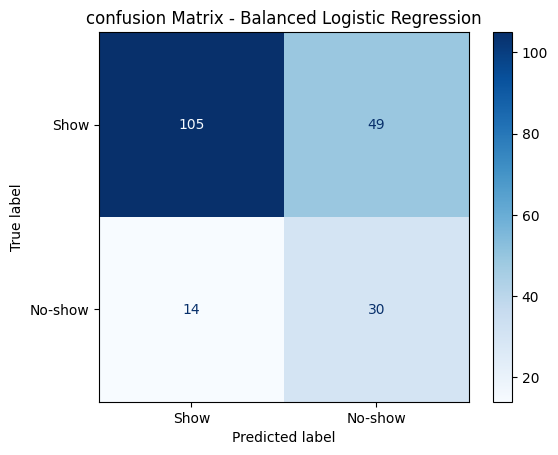

In [39]:
# Confusion Matrix

from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# create confusion matrix
cm = confusion_matrix(y_test, y_pred_balanced)

# Display confusion matrix

disp = ConfusionMatrixDisplay(
    confusion_matrix = cm,
    display_labels = ['Show' , 'No-show']
)

disp.plot(cmap = 'Blues')

plt.title('confusion Matrix - Balanced Logistic Regression')
plt.show()

#Task 3.3 : Decision tree and overfitting

In [40]:
# step 1 :
from sklearn.tree import DecisionTreeClassifier

# create the decision tree model

dt_model = DecisionTreeClassifier(
    random_state = 42
)

# Train the model
dt_model.fit(x_train,y_train)

# Make predictions
y_pred_tree = dt_model.predict(x_test)
print("Decision tree model trained successfully")

Decision tree model trained successfully


In [41]:
# step 2 : evaluate the decision tree model

# calculate accuracy

tree_accuracy = accuracy_score(y_test, y_pred_tree)

print("Decision Tree Accuracy:", tree_accuracy)

# Display classification report

print("\nDecision Tree Classification Report:")

print(classification_report(y_test, y_pred_tree))

Decision Tree Accuracy: 0.7070707070707071

Decision Tree Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.81      0.81       154
           1       0.35      0.36      0.36        44

    accuracy                           0.71       198
   macro avg       0.58      0.58      0.58       198
weighted avg       0.71      0.71      0.71       198



In [42]:
# Step 3 : check for overfitting

#predict on training data

y_train_pred_tree = dt_model.predict(x_train)

# Calculate training accuracy

train_accuracy_tree = accuracy_score(y_train,y_train_pred_tree)

# calculate testing accuracy

test_accuracy_tree = accuracy_score(y_test,y_pred_tree)

print("Training Accuracy:", train_accuracy_tree)

print("Testing Accuracy:",test_accuracy_tree)

# Calculate the difference

print("Accuracy Difference:", train_accuracy_tree - test_accuracy_tree)


Training Accuracy: 1.0
Testing Accuracy: 0.7070707070707071
Accuracy Difference: 0.29292929292929293


In [43]:
# Step 4 : Reduce overfitting

dt_model_limited = DecisionTreeClassifier(
    max_depth = 5,
    random_state = 42
)

# Train the limited model

dt_model_limited.fit(x_train, y_train)

# Make predictions

y_pred_limited = dt_model_limited.predict(x_test)

# Calculate training and testing accuracy
train_accuracy_limited = accuracy_score(
    y_train,
    dt_model_limited.predict(x_train)
)

test_accuracy_limited = accuracy_score(
    y_test,
    y_pred_limited
)

print("Limited Tree Training Accuracy:",train_accuracy_limited)

print("Limited Tree Testing Accuracy:",test_accuracy_limited)

print(
      "Accuracy Difference:",
    train_accuracy_limited - test_accuracy_limited
)


Limited Tree Training Accuracy: 0.8459595959595959
Limited Tree Testing Accuracy: 0.797979797979798
Accuracy Difference: 0.0479797979797979


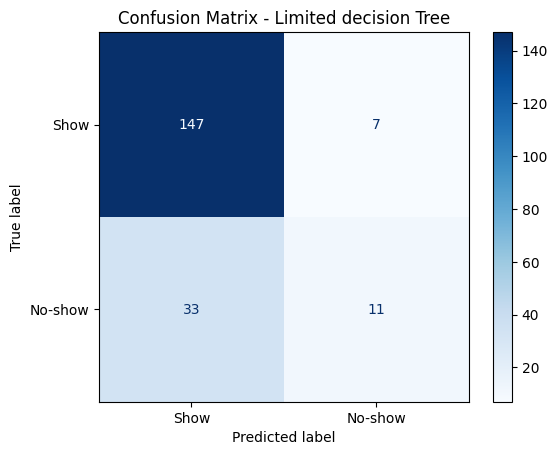

In [44]:
# Step 4 - Confusion matrix for limited tree

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# calculate confusion matrix

cm_limited = confusion_matrix(y_test, y_pred_limited)

# Display confusion matrix

disp = ConfusionMatrixDisplay(
    confusion_matrix = cm_limited,
    display_labels = ['Show', 'No-show']
)

disp.plot(cmap = 'Blues')

plt.title('Confusion Matrix - Limited decision Tree')

plt.show()

##Task 3.4 — Random forest and a comparison table

In [45]:
# Step 1: Compare the models

from sklearn.metrics import accuracy_score, recall_score, f1_score

# Compare model performance
model_comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Balanced Logistic Regression',
        'Decision Tree',
        'Limited Decision Tree'
    ],
    'Accuracy': [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, y_pred_balanced),
        accuracy_score(y_test, y_pred_tree),
        accuracy_score(y_test, y_pred_limited)
    ],
    'No-show Recall': [
        recall_score(y_test, y_pred),
        recall_score(y_test, y_pred_balanced),
        recall_score(y_test, y_pred_tree),
        recall_score(y_test, y_pred_limited)
    ],
    'No-show F1-score': [
        f1_score(y_test, y_pred),
        f1_score(y_test, y_pred_balanced),
        f1_score(y_test, y_pred_tree),
        f1_score(y_test, y_pred_limited)
    ]
})

print(model_comparison.round(2))

                          Model  Accuracy  No-show Recall  No-show F1-score
0           Logistic Regression      0.79            0.34              0.42
1  Balanced Logistic Regression      0.68            0.68              0.49
2                 Decision Tree      0.71            0.36              0.36
3         Limited Decision Tree      0.80            0.25              0.35


In [46]:
# Step 2: Train the Random Forest model

from sklearn.ensemble import RandomForestClassifier

# Create the Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model
rf_model.fit(x_train, y_train)

# Make predictions
y_pred_rf = rf_model.predict(x_test)

print("Random Forest model trained successfully")

Random Forest model trained successfully


## Task 3.5 — Tune, choose the model and the threshold, then test once

In [47]:
# Task 3.5: Feature Importance

# Get feature importance from the Random Forest
feature_importance = pd.DataFrame({
    'Feature': x_train.columns,
    'Importance': rf_model.feature_importances_
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

# Display the top 3 features
print(feature_importance.head(3))

       Feature  Importance
3    lead_days    0.220606
1  distance_km    0.201871
0          age    0.188897


In [48]:
# Step 2: Hyperparameter Tuning

from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

# Define the parameter combinations
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [3, 5, 8]
}

# Create the Random Forest model
rf_model = RandomForestClassifier(random_state=42)

# Perform GridSearchCV
grid_search = GridSearchCV(
    estimator=rf_model,
    param_grid=param_grid,
    cv=5,
    scoring="roc_auc"
)

# Train and find the best parameters
grid_search.fit(x_train, y_train)

# Display the best parameters and ROC-AUC score
print("Best Parameters:", grid_search.best_params_)
print("Best ROC-AUC Score:", grid_search.best_score_)

Best Parameters: {'max_depth': 5, 'n_estimators': 100}
Best ROC-AUC Score: 0.7675065289687867


In [49]:
# Step 3: Compare models using cross-validation

from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
import pandas as pd

# Create the tuned Random Forest
rf_tuned = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    random_state=42
)

# Create the depth-3 Decision Tree
dt_depth3 = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

# Calculate 5-fold cross-validation ROC-AUC
rf_cv_score = cross_val_score(
    rf_tuned,
    x_train,
    y_train,
    cv=5,
    scoring="roc_auc"
).mean()

dt_cv_score = cross_val_score(
    dt_depth3,
    x_train,
    y_train,
    cv=5,
    scoring="roc_auc"
).mean()

print("Random Forest CV ROC-AUC:", rf_cv_score)
print("Decision Tree CV ROC-AUC:", dt_cv_score)

Random Forest CV ROC-AUC: 0.7675065289687867
Decision Tree CV ROC-AUC: 0.6849835315715586


In [50]:
# Step 4 : Logistic Regression cross-validation

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

lr_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(
        class_weight='balanced',
        random_state=42,
        max_iter=1000
    ))
])

lr_cv_score = cross_val_score(
    lr_pipeline,
    x_train,
    y_train,
    cv=5,
    scoring='roc_auc'
).mean()

print("Logistic Regression CV ROC-AUC:", lr_cv_score)

Logistic Regression CV ROC-AUC: 0.7990484895767906


In [51]:
# Step 5: Compare classification thresholds

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd

# Get out-of-fold probabilities using Logistic Regression
y_prob_lr = cross_val_predict(
    lr_pipeline,
    x_train,
    y_train,
    cv=5,
    method='predict_proba'
)[:, 1]

# Compare thresholds
threshold_results = []

for threshold in [0.50, 0.35]:

    # Convert probabilities into predictions
    y_pred_threshold = (y_prob_lr >= threshold).astype(int)

    # Calculate metrics
    precision = precision_score(
        y_train,
        y_pred_threshold,
        pos_label=1
    )

    recall = recall_score(
        y_train,
        y_pred_threshold,
        pos_label=1
    )

    f1 = f1_score(
        y_train,
        y_pred_threshold,
        pos_label=1
    )

    # Count bookings flagged as No-show
    flagged = (y_pred_threshold == 1).sum()

    threshold_results.append({
        'Threshold': threshold,
        'Precision': precision,
        'Recall': recall,
        'F1-score': f1,
        'Number Flagged': flagged
    })

threshold_comparison = pd.DataFrame(threshold_results)

print(threshold_comparison.round(3))

   Threshold  Precision  Recall  F1-score  Number Flagged
0       0.50      0.446   0.718     0.551             280
1       0.35      0.336   0.845     0.480             438


In [52]:
# Step 6: Final Model Evaluation

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Select the final threshold
final_threshold = 0.50

# Train the winning model on the full training data
lr_pipeline.fit(x_train, y_train)

# Get predicted probabilities for the test data
y_prob_final = lr_pipeline.predict_proba(x_test)[:, 1]

# Apply the selected threshold
y_pred_final = (
    y_prob_final >= final_threshold
).astype(int)

# Calculate evaluation metrics
print("Final Model: Balanced Logistic Regression")
print("Selected Threshold:", final_threshold)

print(
    "\nTest Accuracy:",
    accuracy_score(y_test, y_pred_final)
)

print(
    "Test ROC-AUC:",
    roc_auc_score(y_test, y_prob_final)
)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_final))

# Display confusion matrix
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_final))

Final Model: Balanced Logistic Regression
Selected Threshold: 0.5

Test Accuracy: 0.6818181818181818
Test ROC-AUC: 0.7415879574970483

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.68      0.77       154
           1       0.38      0.68      0.49        44

    accuracy                           0.68       198
   macro avg       0.63      0.68      0.63       198
weighted avg       0.77      0.68      0.71       198

Confusion Matrix:
[[105  49]
 [ 14  30]]


In [53]:
print("High-risk patients:", sum(y_pred_balanced))

High-risk patients: 79


In [56]:
# identify high-risk patients
high_risk_patients = x_test[y_pred_balanced == 1].copy()

# Display the high-risk patients
print("Number of high_risk patients:",len(high_risk_patients))

display(high_risk_patients.head(10))


Number of high_risk patients: 79


,age,distance_km,fee_inr,lead_days,prior_no_shows,reminder_sent,booking_channel_Phone,booking_channel_Walk-In,visit_type_Follow-up
218,52,11.7,950.0,33,0,1,0,0,0
695,44,8.3,750.0,8,1,0,1,0,0
250,39,22.9,750.0,21,0,0,0,0,0
432,33,12.0,850.0,20,0,0,1,0,0
860,42,6.3,450.0,12,3,1,1,0,1
714,37,7.2,450.0,20,1,0,0,0,1
208,57,10.2,600.0,18,1,0,1,0,1
273,26,20.7,700.0,16,1,1,0,1,0
1000,24,17.0,550.0,9,2,1,0,0,0
626,35,2.7,1000.0,4,0,0,1,0,0


the balanced Logistic Regression model achieved a test ROC-AUC of 0.742 and 68% recall for no-shows at a 0.50 threshold.

Final Conclusion
The objective of this project was to predict whether a patient would miss a scheduled appointment. I compared Logistic Regression, Decision Tree, and Random Forest models using 5-fold cross-validation with ROC-AUC.

Balanced Logistic Regression was selected based on its cross-validation performance. A classification threshold of 0.50 was chosen because it gave a better F1-score than the 0.35 threshold during threshold comparison.

On the held-out test set, the final model achieved 68.2% accuracy and 0.742 ROC-AUC. It identified 30 of 44 actual no-shows, giving a no-show recall of 68%. However, its no-show precision was 38%, meaning some appointments flagged as likely no-shows would still take place.

The model may help identify patients for additional reminders, but its predictions should be used with consideration for the cost of unnecessary reminders.

In [58]:
# Step 1: Create a copy of the test dataset
high_risk_patients = x_test[y_pred_balanced == 1].copy()

# Step 2: Add the actual no-show status
high_risk_patients["actual_no_show"] = y_test.loc[high_risk_patients.index]

# Step 3: Add the predicted no-show status
high_risk_patients["predicted_no_show"] = 1

# Step 4: Save the results
high_risk_patients.to_csv("high_risk_patients.csv", index=True)

print("High-risk patient predictions saved successfully!")

High-risk patient predictions saved successfully!


In [59]:
import shutil

shutil.copy(
    "high_risk_patients.csv",
    "/content/drive/MyDrive/GenAI_Project_Results/high_risk_patients.csv"
)

print("High-risk patient file saved to Google Drive!")

High-risk patient file saved to Google Drive!
